In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics huggingface_hub torchreid supervision

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from huggingface_hub import snapshot_download

DATA_DIR = "/content/drive/MyDrive/reid_project/uvh26"

if not os.path.exists(DATA_DIR) or not os.listdir(DATA_DIR):
    snapshot_download(
        repo_id="iisc-aim/UVH-26",
        repo_type="dataset",
        local_dir=DATA_DIR,
    )
else:
    print("Dataset already present, skipping download.")

Dataset already present, skipping download.


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/reid_project/uvh26"

for root, dirs, files in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, "").count(os.sep)
    if depth <= 2:
        print(f"{'  '*depth}{os.path.basename(root)}/  ({len(files)} files)")
        for f in files[:3]:
            print(f"{'  '*(depth+1)}{f}")

uvh26/  (3 files)
  dataset_infos.json
  .gitattributes
  README.md
  .cache/  (0 files)
    huggingface/  (2 files)
      .gitignore
      CACHEDIR.TAG
  UVH-26-Val/  (2 files)
    UVH-26-MV-Val.json
    UVH-26-ST-Val.json
    data/  (0 files)
  UVH-26-Train/  (2 files)
    UVH-26-MV-Train.json
    UVH-26-ST-Train.json
    data/  (0 files)


In [ ]:
from huggingface_hub import list_repo_files

for f in list_repo_files("iisc-aim/UVH-26", repo_type="model"):
    print(f)

.gitattributes
README.md
arxiv-logomark-small.svg
banner.png
configs/damo_yolo_l.yml
configs/damo_yolo_t.yml
configs/rtdetrv2_s.yaml
configs/rtdetrv2_x.yaml
configs/yolov11_s.yml
configs/yolov11_x.yml
usage/inference_damo_yolo.py
usage/inference_rtdetrv2.py
usage/inference_yolov11.py
uvh26_model_perf.png
uvh_classes.txt
weights/DAMO-YOLO-L/UVH-26-MV-DAMO-YOLO-L.pth
weights/DAMO-YOLO-T/UVH-26-MV-DAMO-YOLO-T.pth
weights/RT-DETRv2-S/UVH-26-MV-RT-DETRv2-S.pth
weights/RT-DETRv2-X/UVH-26-MV-RT-DETRv2-X.pth
weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt
weights/YOLOv11-X/UVH-26-MV-YOLOv11-X.pt


In [ ]:
import os
from ultralytics import YOLO

coco_model = YOLO("yolo11s.pt")        # stock COCO baseline
# uvh_model = YOLO("<path to downloaded UVH-26 weights>")

# Construct a path to an existing image from the UVH-26 dataset
test_image_dir = "/content/drive/MyDrive/reid_project/uvh26/UVH-26-Val/data/001"
if os.path.exists(test_image_dir) and os.listdir(test_image_dir):
    # Grab the first image available in the folder
    test_image_name = os.listdir(test_image_dir)[0]
    test_image_path = os.path.join(test_image_dir, test_image_name)
    print(f"Using test image: {test_image_path}")
    results = coco_model.predict(test_image_path, conf=0.25, save=True)
else:
    print("Could not find validation images directory. Please provide a valid path to an image.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Using test image: /content/drive/MyDrive/reid_project/uvh26/UVH-26-Val/data/001/994554.png

image 1/1 /content/drive/MyDrive/reid_project/uvh26/UVH-26-Val/data/001/994554.png: 384x640 8 persons, 3 cars, 3 motorcycles, 1 bus, 2 trucks, 17.2ms
Speed: 122.6ms preprocess, 17.2ms inference, 39.4ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict


In [ ]:
from huggingface_hub import hf_hub_download

MODEL_DIR = "/content/drive/MyDrive/reid_project/models"

uvh_weights = hf_hub_download(
    repo_id="iisc-aim/UVH-26",
    repo_type="model",
    filename="weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt",
    local_dir=MODEL_DIR,
)
classes_path = hf_hub_download(
    repo_id="iisc-aim/UVH-26",
    repo_type="model",
    filename="uvh_classes.txt",
    local_dir=MODEL_DIR,
)

print("Weights:", uvh_weights)
print(open(classes_path).read())

Weights: /content/drive/.shortcut-targets-by-id/1WsWL8aO6ooqG5sRixQDz9_IjbOe66Q9P/reid_project/models/weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt
Hatchback
Sedan
SUV
MUV
Bus
Truck
Three-wheeler
Two-wheeler
LCV
Mini-bus
Tempo-traveller
Bicycle
Van
Others


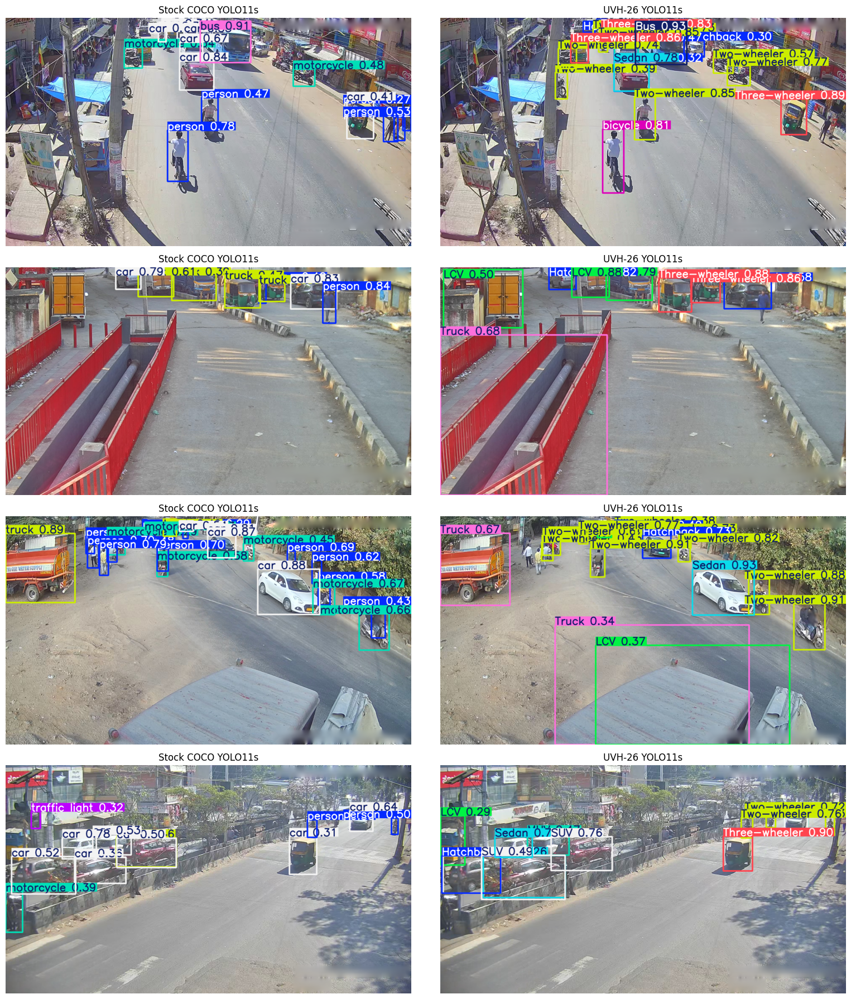

In [ ]:
import os, random
import matplotlib.pyplot as plt
from ultralytics import YOLO

coco_model = YOLO("yolo11s.pt")
uvh_model = YOLO(uvh_weights)

img_root = "/content/drive/MyDrive/reid_project/uvh26/UVH-26-Val/data"
all_imgs = []
for folder in sorted(os.listdir(img_root))[:3]:
    p = os.path.join(img_root, folder)
    if os.path.isdir(p):
        all_imgs += [os.path.join(p, f) for f in os.listdir(p) if f.endswith((".png", ".jpg"))]

random.seed(0)
samples = random.sample(all_imgs, 4)

fig, axes = plt.subplots(len(samples), 2, figsize=(16, 4.5 * len(samples)))
for i, path in enumerate(samples):
    r_coco = coco_model.predict(path, conf=0.25, verbose=False)[0]
    r_uvh = uvh_model.predict(path, conf=0.25, verbose=False)[0]
    axes[i, 0].imshow(r_coco.plot()[:, :, ::-1])
    axes[i, 0].set_title("Stock COCO YOLO11s")
    axes[i, 1].imshow(r_uvh.plot()[:, :, ::-1])
    axes[i, 1].set_title("UVH-26 YOLO11s")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import json

ann_path = "/content/drive/MyDrive/reid_project/uvh26/UVH-26-Val/UVH-26-MV-Val.json"
with open(ann_path) as f:
    ann = json.load(f)

print("Top-level keys:", list(ann.keys()))
for k, v in ann.items():
    if isinstance(v, list):
        print(f"{k}: {len(v)} items")
print("\nCategories:", ann.get("categories"))
print("\nSample image entry:", ann["images"][0])
print("\nSample annotation:", ann["annotations"][0])

Top-level keys: ['info', 'licenses', 'images', 'annotations', 'categories']
licenses: 1 items
images: 5297 items
annotations: 63497 items
categories: 14 items

Categories: [{'id': 1, 'name': 'Hatchback', 'supercategory': 'vehicle'}, {'id': 2, 'name': 'Sedan', 'supercategory': 'vehicle'}, {'id': 3, 'name': 'SUV', 'supercategory': 'vehicle'}, {'id': 4, 'name': 'MUV', 'supercategory': 'vehicle'}, {'id': 5, 'name': 'Bus', 'supercategory': 'vehicle'}, {'id': 6, 'name': 'Truck', 'supercategory': 'vehicle'}, {'id': 7, 'name': 'Three-wheeler', 'supercategory': 'vehicle'}, {'id': 8, 'name': 'Two-wheeler', 'supercategory': 'vehicle'}, {'id': 9, 'name': 'LCV', 'supercategory': 'vehicle'}, {'id': 10, 'name': 'Mini-bus', 'supercategory': 'vehicle'}, {'id': 11, 'name': 'Tempo-traveller', 'supercategory': 'vehicle'}, {'id': 12, 'name': 'Bicycle', 'supercategory': 'vehicle'}, {'id': 13, 'name': 'Van', 'supercategory': 'vehicle'}, {'id': 14, 'name': 'Others', 'supercategory': 'vehicle'}]

Sample image 

In [ ]:
!pip install -q pycocotools
import os, json, random, shutil, time
from collections import defaultdict

ROOT = "/content/drive/MyDrive/reid_project/uvh26/UVH-26-Val"
ann = json.load(open(f"{ROOT}/UVH-26-MV-Val.json"))

path_of = {}
for r, _, fs in os.walk(f"{ROOT}/data"):
    for f in fs:
        path_of[f] = os.path.join(r, f)
print("images on disk:", len(path_of), "| in JSON:", len(ann["images"]))

N = 300
random.seed(42)
imgs = [im for im in ann["images"] if im["file_name"] in path_of]
sample = random.sample(imgs, N)
sample_ids = {im["id"] for im in sample}

LOCAL = "/content/val_sample"
os.makedirs(LOCAL, exist_ok=True)
for im in sample:
    dst = f"{LOCAL}/{im['file_name']}"
    if not os.path.exists(dst):
        src = path_of[im["file_name"]]
        # Robust retry loop to handle Google Drive temporary I/O dropouts
        for attempt in range(5):
            try:
                shutil.copy(src, dst)
                break
            except OSError as e:
                if attempt == 4:
                    raise e
                time.sleep(1) # wait 1 second before retrying
    im["local"] = dst

fname2id = {im["file_name"]: im["id"] for im in sample}
gt_anns = [a for a in ann["annotations"] if a["image_id"] in sample_ids]
id2name = {c["id"]: c["name"] for c in ann["categories"]}
print(len(gt_anns), "ground-truth boxes in sample")

images on disk: 5297 | in JSON: 5297
3331 ground-truth boxes in sample


In [ ]:
import numpy as np
from ultralytics import YOLO
import os
import shutil
import time
from PIL import Image

uvh_model = YOLO(uvh_weights)
coco_model = YOLO("yolo11s.pt")
print(uvh_model.names)

# Convert all names to lowercase to avoid casing mismatch assertions
fine_names_lower = [c["name"].lower() for c in ann["categories"]]
model_names_lower = [name.lower() for name in uvh_model.names.values()]

assert set(model_names_lower) <= set(fine_names_lower), "Class names don't match the JSON!"

# --- Corrupted Image Clean Up & Recovery ---
# Verify all local files in the sample; if any are corrupted (or size 0), remove them and re-copy
print("Verifying local sample images...")
for im in sample:
    dst = im["local"]
    is_corrupt = False
    if not os.path.exists(dst) or os.path.getsize(dst) == 0:
        is_corrupt = True
    else:
        try:
            with Image.open(dst) as img:
                img.verify() # Check if image is valid
        except Exception:
            is_corrupt = True

    if is_corrupt:
        if os.path.exists(dst):
            os.remove(dst)
        src = path_of[im["file_name"]]
        print(f"Re-copying damaged/missing image: {im['file_name']}")
        for attempt in range(5):
            try:
                shutil.copy(src, dst)
                break
            except OSError as e:
                if attempt == 4:
                    raise e
                time.sleep(1)

IMGSZ = 640

def run_model(model, classes=None):
    dets, paths = [], [im["local"] for im in sample]
    for i in range(0, len(paths), 16):
        batch = paths[i:i+16]
        results = model.predict(batch, conf=0.001, iou=0.6, imgsz=IMGSZ,
                                classes=classes, verbose=False)
        for p, r in zip(batch, results):
            img_id = fname2id[os.path.basename(p)]
            xyxy = r.boxes.xyxy.cpu().numpy()
            sc = r.boxes.conf.cpu().numpy()
            cl = r.boxes.cls.cpu().numpy().astype(int)
            for (x1, y1, x2, y2), s, c in zip(xyxy, sc, cl):
                dets.append(dict(image_id=img_id, name=model.names[c],
                                 bbox=[float(x1), float(y1), float(x2-x1), float(y2-y1)],
                                 score=float(s)))
    return dets

uvh_dets = run_model(uvh_model)
coco_dets = run_model(coco_model, classes=[1, 2, 3, 5, 7])  # bicycle, car, motorcycle, bus, truck
print(len(uvh_dets), "UVH detections |", len(coco_dets), "COCO detections")

{0: 'Hatchback', 1: 'Sedan', 2: 'SUV', 3: 'MUV', 4: 'Bus', 5: 'Truck', 6: 'Three-wheeler', 7: 'Two-wheeler', 8: 'LCV', 9: 'Mini-bus', 10: 'tempo-traveller', 11: 'bicycle', 12: 'Van', 13: 'Others'}
Verifying local sample images...
15905 UVH detections | 44235 COCO detections


In [ ]:
import io, contextlib, torch, pandas as pd
import numpy as np
from collections import defaultdict
from torchvision.ops import nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Define fine_names from categories metadata
fine_names = [c["name"] for c in ann["categories"]]

def evaluate(gt, dets, classes):
    cid = {n: i+1 for i, n in enumerate(classes)}
    g = [dict(id=k+1, image_id=a["image_id"], category_id=cid[a["name"]], bbox=a["bbox"],
              area=a["bbox"][2]*a["bbox"][3], iscrowd=0)
         for k, a in enumerate(x for x in gt if x["name"] in cid)]
    d = [dict(image_id=x["image_id"], category_id=cid[x["name"]], bbox=x["bbox"], score=x["score"])
         for x in dets if x["name"] in cid]
    with contextlib.redirect_stdout(io.StringIO()):
        gtc = COCO()
        gtc.dataset = dict(images=[{"id": i} for i in sample_ids], annotations=g,
                           categories=[{"id": v, "name": k} for k, v in cid.items()])
        gtc.createIndex()
        dtc = gtc.loadRes(d)
        E = COCOeval(gtc, dtc, "bbox")
        E.params.imgIds = sorted(sample_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    P = E.eval["precision"]  # [IoU, recall, class, area, maxDets]
    out = {}
    for k, n in enumerate(classes):
        p50, pall = P[0, :, k, 0, 2], P[:, :, k, 0, 2]
        out[n] = (p50[p50 > -1].mean() if (p50 > -1).any() else np.nan,
                  pall[pall > -1].mean() if (pall > -1).any() else np.nan)
    out["ALL"] = (E.stats[1], E.stats[0])   # mAP50, mAP50:95
    return out

def remap(dets, mapping, nms_iou=0.6):
    """Rename to coarse classes and merge duplicates (e.g. Sedan+SUV on one car)."""
    by = defaultdict(list)
    for d in dets:
        if d["name"] in mapping:
            by[(d["image_id"], mapping[d["name"]])].append(d)
    out = []
    for (_, cn), ds in by.items():
        boxes = torch.tensor([[x["bbox"][0], x["bbox"][1],
                               x["bbox"][0]+x["bbox"][2], x["bbox"][1]+x["bbox"][3]] for x in ds])
        keep = nms(boxes, torch.tensor([x["score"] for x in ds]), nms_iou)
        out += [dict(ds[i], name=cn) for i in keep.tolist()]
    return out

# ---- A) UVH-26 model, all 14 fine classes ----
gt_f = [dict(a, name=id2name[a["category_id"]]) for a in gt_anns]
r_fine = evaluate(gt_f, uvh_dets, fine_names)
df_fine = pd.DataFrame([(n, *r_fine[n]) for n in fine_names + ["ALL"]],
                       columns=["class", "AP50", "AP50:95"]).round(3)
print("UVH-26 YOLO11s, fine-grained:")
display(df_fine)

# ---- B) Head-to-head on coarse classes (COCO can't do finer) ----
FINE2COARSE = {"Hatchback": "Car-like", "Sedan": "Car-like", "SUV": "Car-like", "MUV": "Car-like",
               "Van": "Car-like", "Bus": "Bus-like", "Mini-bus": "Bus-like",
               "Tempo-traveller": "Bus-like", "Truck": "Truck-like", "LCV": "Truck-like",
               "Two-wheeler": "Two-wheeler", "Three-wheeler": "Three-wheeler", "Bicycle": "Bicycle"}
COCO2COARSE = {"car": "Car-like", "bus": "Bus-like", "truck": "Truck-like",
               "motorcycle": "Two-wheeler", "bicycle": "Bicycle"}
coarse = ["Car-like", "Bus-like", "Truck-like", "Two-wheeler", "Three-wheeler", "Bicycle"]

gt_c = [dict(a, name=FINE2COARSE[id2name[a["category_id"]]])
        for a in gt_anns if id2name[a["category_id"]] in FINE2COARSE]
r_u = evaluate(gt_c, remap(uvh_dets, FINE2COARSE), coarse)
r_c = evaluate(gt_c, remap(coco_dets, COCO2COARSE), coarse)

df_cmp = pd.DataFrame([(n, r_c[n][0], r_u[n][0], r_c[n][1], r_u[n][1]) for n in coarse + ["ALL"]],
                      columns=["class", "COCO AP50", "UVH AP50", "COCO AP50:95", "UVH AP50:95"]).round(3)
print("\nCoarse head-to-head (stock COCO vs UVH-26):")
display(df_cmp)

UVH-26 YOLO11s, fine-grained:


,class,AP50,AP50:95
0,Hatchback,0.610,0.520
1,Sedan,0.552,0.495
2,SUV,0.403,0.307
3,MUV,0.315,0.282
4,Bus,0.683,0.510
5,Truck,0.450,0.259
6,Three-wheeler,0.887,0.728
7,Two-wheeler,0.906,0.677
8,LCV,0.635,0.492
9,Mini-bus,0.162,0.162



Coarse head-to-head (stock COCO vs UVH-26):


,class,COCO AP50,UVH AP50,COCO AP50:95,UVH AP50:95
0,Car-like,0.775,0.887,0.599,0.746
1,Bus-like,0.446,0.617,0.358,0.454
2,Truck-like,0.463,0.707,0.352,0.475
3,Two-wheeler,0.403,0.906,0.135,0.677
4,Three-wheeler,0.000,0.893,0.000,0.728
5,Bicycle,0.227,0.000,0.053,0.000
6,ALL,0.386,0.668,0.250,0.513


GT boxes per class (sample):
{'Hatchback': 295, 'Sedan': 158, 'SUV': 119, 'MUV': 67, 'Bus': 98, 'Truck': 159, 'Three-wheeler': 517, 'Two-wheeler': 1623, 'LCV': 192, 'Mini-bus': 9, 'Tempo-traveller': 15, 'Bicycle': 45, 'Van': 27, 'Others': 7}

UVH-26 at imgsz=1280:


,class,AP50,AP50:95
0,Hatchback,0.499,0.391
1,Sedan,0.546,0.439
2,SUV,0.359,0.256
3,MUV,0.282,0.220
4,Bus,0.558,0.361
5,Truck,0.351,0.185
6,Three-wheeler,0.803,0.592
7,Two-wheeler,0.889,0.665
8,LCV,0.506,0.326
9,Mini-bus,0.228,0.228



Precision / recall at conf >= 0.4, IoU >= 0.5:


,class,precision,recall,GT boxes
0,Hatchback,0.527,0.427,295
1,Sedan,0.490,0.595,158
2,SUV,0.384,0.487,119
3,MUV,0.309,0.254,67
4,Bus,0.562,0.551,98
5,Truck,0.429,0.421,159
6,Three-wheeler,0.769,0.805,517
7,Two-wheeler,0.848,0.793,1623
8,LCV,0.466,0.531,192
9,Mini-bus,0.000,0.000,9


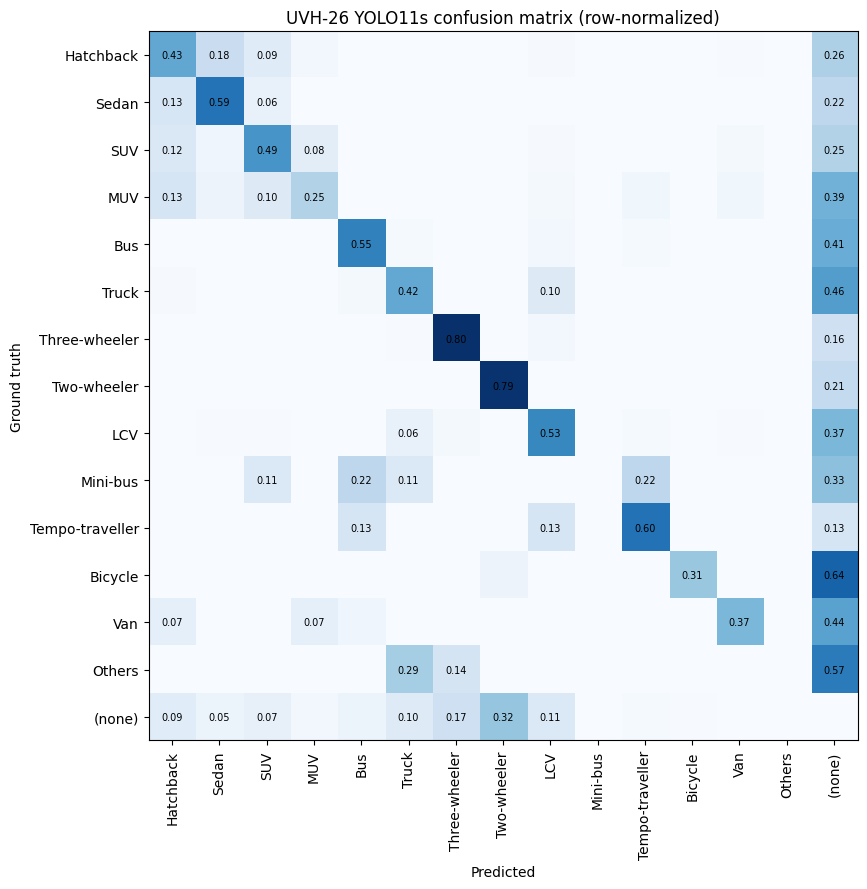

In [ ]:
from collections import Counter
from torchvision.ops import box_iou
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import defaultdict
import torch

# ---- 1) Ground-truth counts in the 300-image sample ----
cnt = Counter(a["name"] for a in gt_f)
print("GT boxes per class (sample):")
print({n: cnt.get(n, 0) for n in fine_names})

# ---- 2) Re-run UVH-26 at higher resolution and re-evaluate ----
IMGSZ = 1280
uvh_dets_1280 = run_model(uvh_model)
r1280 = evaluate(gt_f, uvh_dets_1280, fine_names)
df_1280 = pd.DataFrame([(n, *r1280[n]) for n in fine_names + ["ALL"]],
                       columns=["class", "AP50", "AP50:95"]).round(3)
print("\nUVH-26 at imgsz=1280:")
display(df_1280)

# ---- 3) Confusion matrix + precision/recall at conf >= 0.4 ----
CONF, IOU_T = 0.4, 0.5
# Use lowercased names for matching mapping lookups safely
names_lower = [n.lower() for n in fine_names] + ["(none)"]
idx = {n: i for i, n in enumerate(names_lower)}
BG = idx["(none)"]
cm = np.zeros((len(names_lower), len(names_lower)), int)   # rows = ground truth, cols = prediction

dets_by_img, gt_by_img = defaultdict(list), defaultdict(list)
for d in uvh_dets_1280:
    if d["score"] >= CONF:
        dets_by_img[d["image_id"]].append(d)
for a in gt_f:
    gt_by_img[a["image_id"]].append(a)

def xyxy(b): return [b[0], b[1], b[0] + b[2], b[1] + b[3]]

for iid in sample_ids:
    g = gt_by_img[iid]
    d = sorted(dets_by_img[iid], key=lambda x: -x["score"])
    used = set()
    if g and d:
        iou = box_iou(torch.tensor([xyxy(x["bbox"]) for x in d]),
                      torch.tensor([xyxy(a["bbox"]) for a in g]))
        for i, det in enumerate(d):
            row = iou[i].clone()
            for j in used:
                row[j] = -1
            j = int(row.argmax())
            if row[j] >= IOU_T:
                cm[idx[g[j]["name"].lower()], idx[det["name"].lower()]] += 1
                used.add(j)
            else:
                cm[BG, idx[det["name"].lower()]] += 1      # false positive
    else:
        for det in d:
            cm[BG, idx[det["name"].lower()]] += 1
    for j, a in enumerate(g):
        if j not in used:
            cm[idx[a["name"].lower()], BG] += 1            # missed

tp = np.diag(cm)[:-1]
prec = tp / np.maximum(cm[:, :-1].sum(0), 1)
rec = tp / np.maximum(cm[:-1, :].sum(1), 1)
print(f"\nPrecision / recall at conf >= {CONF}, IoU >= {IOU_T}:")
display(pd.DataFrame({"class": fine_names, "precision": prec.round(3),
                      "recall": rec.round(3), "GT boxes": cm[:-1, :].sum(1)}))

cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cmn, cmap="Blues")
ax.set_xticks(range(len(names_lower))); ax.set_xticklabels(fine_names + ["(none)"], rotation=90)
ax.set_yticks(range(len(names_lower))); ax.set_yticklabels(fine_names + ["(none)"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Ground truth")
ax.set_title("UVH-26 YOLO11s confusion matrix (row-normalized)")
for i in range(len(names_lower)):
    for j in range(len(names_lower)):
        if cmn[i, j] > 0.05:
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
canon = {n.lower(): n for n in fine_names}
print("Model class names:", uvh_model.names)

def fix_names(dets):
    for d in dets:
        d["name"] = canon[d["name"].lower()]

fix_names(uvh_dets)
fix_names(uvh_dets_1280)
print("Names fixed. Unique names in detections:", sorted({d["name"] for d in uvh_dets}))

Model class names: {0: 'Hatchback', 1: 'Sedan', 2: 'SUV', 3: 'MUV', 4: 'Bus', 5: 'Truck', 6: 'Three-wheeler', 7: 'Two-wheeler', 8: 'LCV', 9: 'Mini-bus', 10: 'tempo-traveller', 11: 'bicycle', 12: 'Van', 13: 'Others'}
Names fixed. Unique names in detections: ['Bicycle', 'Bus', 'Hatchback', 'LCV', 'MUV', 'Mini-bus', 'Others', 'SUV', 'Sedan', 'Tempo-traveller', 'Three-wheeler', 'Truck', 'Two-wheeler', 'Van']


In [ ]:
IMGSZ = 640   # back to the model's native size

def confusion(dets, conf=0.4, iou_t=0.5):
    names_l = fine_names + ["(none)"]
    idx = {n: i for i, n in enumerate(names_l)}
    BG = idx["(none)"]
    cm = np.zeros((len(names_l), len(names_l)), int)
    d_by, g_by = defaultdict(list), defaultdict(list)
    for d in dets:
        if d["score"] >= conf:
            d_by[d["image_id"]].append(d)
    for a in gt_f:
        g_by[a["image_id"]].append(a)
    for iid in sample_ids:
        g = g_by[iid]
        d = sorted(d_by[iid], key=lambda x: -x["score"])
        used = set()
        if g and d:
            iou = box_iou(torch.tensor([xyxy(x["bbox"]) for x in d]),
                          torch.tensor([xyxy(a["bbox"]) for a in g]))
            for i, det in enumerate(d):
                row = iou[i].clone()
                for j in used:
                    row[j] = -1
                j = int(row.argmax())
                if row[j] >= iou_t:
                    cm[idx[g[j]["name"]], idx[det["name"]]] += 1
                    used.add(j)
                else:
                    cm[BG, idx[det["name"]]] += 1
        else:
            for det in d:
                cm[BG, idx[det["name"]]] += 1
        for j, a in enumerate(g):
            if j not in used:
                cm[idx[a["name"]], BG] += 1
    return cm

def manual_ap50(gt, dets, classes, iou_t=0.5):
    out = {}
    for c in classes:
        g_by = defaultdict(list)
        for a in gt:
            if a["name"] == c:
                g_by[a["image_id"]].append(xyxy(a["bbox"]))
        n_gt = sum(len(v) for v in g_by.values())
        if n_gt == 0:
            out[c] = np.nan
            continue
        ds = sorted([d for d in dets if d["name"] == c], key=lambda d: -d["score"])
        used = {k: np.zeros(len(v), bool) for k, v in g_by.items()}
        tp = np.zeros(len(ds))
        for i, d in enumerate(ds):
            gb = g_by.get(d["image_id"])
            if not gb:
                continue
            iou = box_iou(torch.tensor([xyxy(d["bbox"])]), torch.tensor(gb))[0].numpy()
            iou[used[d["image_id"]]] = -1
            j = int(iou.argmax())
            if iou[j] >= iou_t:
                tp[i] = 1
                used[d["image_id"]][j] = True
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec = ctp / n_gt
        prec = ctp / np.maximum(ctp + cfp, 1e-9)
        mrec = np.concatenate([[0], rec, [1]])
        mpre = np.concatenate([[0], prec, [0]])
        for k in range(len(mpre) - 2, -1, -1):
            mpre[k] = max(mpre[k], mpre[k + 1])
        ii = np.where(mrec[1:] != mrec[:-1])[0]
        out[c] = float(((mrec[ii + 1] - mrec[ii]) * mpre[ii + 1]).sum())
    return out

# uvh_dets = the 640 detections from the earlier Cell 2
cm640 = confusion(uvh_dets, conf=0.4)
tp = np.diag(cm640)[:-1]
prec = tp / np.maximum(cm640[:, :-1].sum(0), 1)
rec = tp / np.maximum(cm640[:-1, :].sum(1), 1)

ap_manual = manual_ap50(gt_f, uvh_dets, fine_names)
n_dets_hi = Counter(d["name"] for d in uvh_dets if d["score"] >= 0.4)

display(pd.DataFrame({
    "class": fine_names,
    "GT boxes": cm640[:-1, :].sum(1),
    "dets >=0.4": [n_dets_hi.get(n, 0) for n in fine_names],
    "precision@0.4": prec.round(3),
    "recall@0.4": rec.round(3),
    "AP50 (manual)": [round(ap_manual[n], 3) for n in fine_names],
    "AP50 (pycocotools)": [round(r_fine[n][0], 3) for n in fine_names],
}))

,class,GT boxes,dets >=0.4,precision@0.4,recall@0.4,AP50 (manual),AP50 (pycocotools)
0,Hatchback,295,253,0.589,0.505,0.610,0.610
1,Sedan,158,147,0.565,0.525,0.552,0.552
2,SUV,119,69,0.594,0.345,0.403,0.403
3,MUV,67,50,0.420,0.313,0.315,0.315
4,Bus,98,95,0.663,0.643,0.686,0.683
5,Truck,159,118,0.576,0.428,0.450,0.450
6,Three-wheeler,517,451,0.902,0.787,0.890,0.887
7,Two-wheeler,1623,1262,0.936,0.728,0.910,0.906
8,LCV,192,187,0.620,0.604,0.636,0.635
9,Mini-bus,9,1,1.000,0.111,0.156,0.162


In [ ]:
r_fine = evaluate(gt_f, uvh_dets, fine_names)
df_fine = pd.DataFrame([(n, *r_fine[n]) for n in fine_names + ["ALL"]],
                       columns=["class", "AP50", "AP50:95"]).round(3)
print("UVH-26 YOLO11s @640, fine-grained (names fixed):")
display(df_fine)

r_u = evaluate(gt_c, remap(uvh_dets, FINE2COARSE), coarse)
df_cmp = pd.DataFrame([(n, r_c[n][0], r_u[n][0], r_c[n][1], r_u[n][1]) for n in coarse + ["ALL"]],
                      columns=["class", "COCO AP50", "UVH AP50", "COCO AP50:95", "UVH AP50:95"]).round(3)
print("\nCoarse head-to-head (names fixed):")
display(df_cmp)

UVH-26 YOLO11s @640, fine-grained (names fixed):


,class,AP50,AP50:95
0,Hatchback,0.610,0.520
1,Sedan,0.552,0.495
2,SUV,0.403,0.307
3,MUV,0.315,0.282
4,Bus,0.683,0.510
5,Truck,0.450,0.259
6,Three-wheeler,0.887,0.728
7,Two-wheeler,0.906,0.677
8,LCV,0.635,0.492
9,Mini-bus,0.162,0.162



Coarse head-to-head (names fixed):


,class,COCO AP50,UVH AP50,COCO AP50:95,UVH AP50:95
0,Car-like,0.775,0.887,0.599,0.746
1,Bus-like,0.446,0.712,0.358,0.534
2,Truck-like,0.463,0.707,0.352,0.475
3,Two-wheeler,0.403,0.906,0.135,0.677
4,Three-wheeler,0.000,0.893,0.000,0.728
5,Bicycle,0.227,0.585,0.053,0.441
6,ALL,0.386,0.782,0.250,0.600


In [ ]:
import os, cv2

VIDEO = "/content/drive/MyDrive/reid_project/videos/cam1.mp4"
print("exists:", os.path.exists(VIDEO))
print("folder contents:", os.listdir(os.path.dirname(VIDEO)) if os.path.exists(os.path.dirname(VIDEO)) else "folder missing")

cap = cv2.VideoCapture(VIDEO)
print("opened:", cap.isOpened(), "| frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT), "| fps:", cap.get(cv2.CAP_PROP_FPS))

exists: True
folder contents: ['cam1.mp4']
opened: True | frames: 812.0 | fps: 30.0


In [ ]:
!pip install -q ultralytics
import os, cv2, json, subprocess
import numpy as np
from collections import Counter, defaultdict
from ultralytics import YOLO

ROOT = "/content/drive/MyDrive/reid_project"
WEIGHTS = f"{ROOT}/models/weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt"
VIDEO = f"{ROOT}/videos/cam1.mp4"
CAM = "cam1"
OUT = f"{ROOT}/tracks/{CAM}"
os.makedirs(f"{OUT}/crops", exist_ok=True)

open("/content/bytetrack_custom.yaml", "w").write("""tracker_type: bytetrack
track_high_thresh: 0.4
track_low_thresh: 0.1
new_track_thresh: 0.5
track_buffer: 60
match_thresh: 0.8
fuse_score: True
""")

fine = ["Hatchback", "Sedan", "SUV", "MUV", "Bus", "Truck", "Three-wheeler", "Two-wheeler",
        "LCV", "Mini-bus", "Tempo-traveller", "Bicycle", "Van", "Others"]
canon = {n.lower(): n for n in fine}
MIN_SPAN, TOP_K = 15, 5

model = YOLO(WEIGHTS)
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

per_frame = defaultdict(list)
# frame -> [(tid, x1, y1, x2, y2)]
tracks = defaultdict(lambda: dict(first=None, last=None, classes=Counter(), crops=[]))

fi = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = model.track(frame, persist=True, tracker="/content/bytetrack_custom.yaml",
                    conf=0.1, imgsz=640, verbose=False)[0]
    if r.boxes.id is not None:
        for b, tid, c, s in zip(r.boxes.xyxy.cpu().numpy(),
                                r.boxes.id.cpu().numpy().astype(int),
                                r.boxes.cls.cpu().numpy().astype(int),
                                r.boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = [int(v) for v in b]
            x1, y1 = max(x1, 0), max(y1, 0)
            t = tracks[tid]
            t["first"] = fi if t["first"] is None else t["first"]
            t["last"] = fi
            t["classes"][canon[model.names[c].lower()]] += 1
            per_frame[fi].append((tid, x1, y1, x2, y2))
            crop = frame[y1:y2, x1:x2]
            if crop.size:
                t["crops"].append(((x2 - x1) * (y2 - y1) * float(s), fi, crop.copy()))
                t["crops"] = sorted(t["crops"], key=lambda x: -x[0])[:TOP_K]
    fi += 1
cap.release()

keep = {tid for tid, t in tracks.items() if t["last"] - t["first"] + 1 >= MIN_SPAN}
label = {tid: tracks[tid]["classes"].most_common(1)[0][0] for tid in tracks}

# second pass: draw only the kept tracks
raw = "/content/cam1_raw.mp4"
writer = cv2.VideoWriter(raw, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
cap = cv2.VideoCapture(VIDEO)
for i in range(fi):
    ok, frame = cap.read()
    if not ok:
        break
    for tid, x1, y1, x2, y2 in per_frame.get(i, []):
        if tid in keep:
            # Ensure the color values are native Python ints to prevent OpenCV crash
            col = (int((tid * 37) % 200 + 55),
                   int((tid * 91) % 200 + 55),
                   int((tid * 53) % 200 + 55))
            cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
            cv2.putText(frame, f"{tid} {label[tid]}", (x1, max(y1 - 6, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
    writer.write(frame)
cap.release(); writer.release()

final = f"{OUT}/{CAM}_tracked.mp4"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", raw, "-vf", "scale=1280:-2",
                "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "23", final], check=True)

summary = {}
for tid in keep:
    t = tracks[tid]
    for k, (_, f_, crop) in enumerate(t["crops"]):
        cv2.imwrite(f"{OUT}/crops/{CAM}_id{tid:04d}_{label[tid]}_f{f_}_{k}.jpg", crop)
    summary[int(tid)] = dict(cls=label[tid], first=t["first"], last=t["last"],
                             span=t["last"] - t["first"] + 1)
json.dump(summary, open(f"{OUT}/summary.json", "w"), indent=1)

print(f"{fi} frames | raw tracks: {len(tracks)} | kept (>= {MIN_SPAN} frames): {len(keep)}")
print(Counter(v["cls"] for v in summary.values()))
print("Saved:", final)

from IPython.display import Video
Video(final, embed=True, width=800)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 387ms
Prepared 1 package in 304ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

812 frames | raw tracks: 177 | kept (>= 15 frames): 121
Counter({'Two-wheeler': 41, 'Hatchback': 38, 'Three-wheeler': 12, 'Sedan': 11, 'SUV': 8, 'LCV': 7, 'Bus': 2, 'Truck': 2})
Saved: /content/drive/MyDrive/reid_project/tracks/cam1/cam1_tracked.mp4


In [ ]:
import os, zipfile, glob

ZIP = "/content/drive/MyDrive/reid_project/VeRi.zip"
VERI = "/content/veri"

print("zip exists:", os.path.exists(ZIP))
if not os.path.exists(ZIP):
    print(os.listdir("/content/drive/MyDrive/reid_project"))   # check the exact file name

if not os.path.exists(VERI) or not os.listdir(VERI):
    os.makedirs(VERI, exist_ok=True)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(VERI)
    print("Extracted.")
else:
    print("Already extracted, skipping.")

# inspect the layout
for root, dirs, files in os.walk(VERI):
    depth = root.replace(VERI, "").count(os.sep)
    if depth <= 3:
        print(f"{'  '*depth}{os.path.basename(root)}/  ({len(files)} files, {len(dirs)} dirs)")
        for f in sorted(files)[:3]:
            print(f"{'  '*(depth+1)}{f}")

In [ ]:
import os, numpy as np, torch, torchvision
import torch.nn.functional as F
from torchvision import transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader

R = "/content/veri/VeRi"
device = "cuda" if torch.cuda.is_available() else "cpu"

def parse(folder):
    fs = sorted(f for f in os.listdir(folder) if f.endswith(".jpg"))
    ids  = np.array([int(f.split("_")[0]) for f in fs])
    cams = np.array([int(f.split("_")[1][1:]) for f in fs])
    return [os.path.join(folder, f) for f in fs], ids, cams

q_paths, q_ids, q_cams = parse(f"{R}/image_query")
g_paths, g_ids, g_cams = parse(f"{R}/image_test")
print(len(q_paths), "queries |", len(g_paths), "gallery")

tf = T.Compose([T.Resize((256, 256)), T.ToTensor(),
                T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class Imgs(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return tf(Image.open(self.paths[i]).convert("RGB"))

@torch.no_grad()
def extract(model, paths, bs=128):
    model.eval().to(device)
    out = []
    # Use num_workers=0 to prevent TPU/PjRt multiprocess lockfile clashes in Colab
    for x in DataLoader(Imgs(paths), batch_size=bs, num_workers=0):
        out.append(model(x.to(device)).float().cpu())
    return F.normalize(torch.cat(out), dim=1)

def reid_metrics(qf, qid, qcam, gf, gid, gcam):
    dist = (1 - qf @ gf.T).numpy()
    cmc = np.zeros(len(gid)); aps = []
    for i in range(len(qid)):
        order = np.argsort(dist[i])
        same = gid[order] == qid[i]
        junk = same & (gcam[order] == qcam[i])      # same vehicle, same camera -> ignore
        hits = same[~junk]
        if hits.sum() == 0:
            continue
        first = np.where(hits)[0][0]
        cmc[first:] += 1
        prec = np.cumsum(hits) / (np.arange(len(hits)) + 1)
        aps.append(prec[hits].mean())
    n = len(aps)
    return dict(rank1=cmc[0] / n, rank5=cmc[4] / n, rank10=cmc[9] / n, mAP=float(np.mean(aps)))

backbone = torchvision.models.resnet50(weights="IMAGENET1K_V2")
backbone.fc = torch.nn.Identity()

qf = extract(backbone, q_paths)
gf = extract(backbone, g_paths)
print({k: round(v, 3) for k, v in reid_metrics(qf, q_ids, q_cams, gf, g_ids, g_cams).items()})

In [ ]:
import random, time, torch.nn as nn
from collections import defaultdict

assert torch.cuda.is_available(), "Switch to a T4 GPU runtime first!"
CKPT = "/content/drive/MyDrive/reid_project/models/reid_resnet50_veri.pt"

tr_paths, tr_ids, tr_cams = parse(f"{R}/image_train")
uid = sorted(set(tr_ids)); id2lbl = {v: i for i, v in enumerate(uid)}
labels = np.array([id2lbl[i] for i in tr_ids])
by_id = defaultdict(list)
for i, l in enumerate(labels):
    by_id[l].append(i)
print(len(tr_paths), "train images,", len(uid), "vehicles")

train_tf = T.Compose([T.Resize((256, 256)), T.RandomHorizontalFlip(),
                      T.Pad(10), T.RandomCrop((256, 256)), T.ToTensor(),
                      T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
                      T.RandomErasing(p=0.5)])

class TrainSet(Dataset):
    def __len__(self): return len(tr_paths)
    def __getitem__(self, i):
        return train_tf(Image.open(tr_paths[i]).convert("RGB")), int(labels[i])

class PKBatches(torch.utils.data.Sampler):
    """P vehicles x K images per batch, needed for triplet loss."""
    def __init__(self, P=16, K=4, iters=300):
        self.P, self.K, self.iters = P, K, iters
    def __len__(self): return self.iters
    def __iter__(self):
        ids = list(by_id.keys())
        for _ in range(self.iters):
            batch = []
            for l in random.sample(ids, self.P):
                pool = by_id[l]
                batch += random.choices(pool, k=self.K) if len(pool) < self.K else random.sample(pool, self.K)
            yield batch

class ReIDNet(nn.Module):
    def __init__(self, n_cls):
        super().__init__()
        r = torchvision.models.resnet50(weights="IMAGENET1K_V2")
        self.body = nn.Sequential(*list(r.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.bn = nn.BatchNorm1d(2048); self.bn.bias.requires_grad_(False)
        self.fc = nn.Linear(2048, n_cls, bias=False)
    def forward(self, x):
        f = self.pool(self.body(x)).flatten(1)
        fb = self.bn(f)
        return (f, self.fc(fb)) if self.training else fb

def batch_hard_triplet(f, y, margin=0.3):
    f = F.normalize(f.float(), dim=1)
    d = torch.cdist(f, f)
    same = y[:, None] == y[None, :]
    d_pos = (d * same).max(1)[0]
    d_neg = (d + 1e6 * same).min(1)[0]
    return F.relu(d_pos - d_neg + margin).mean()

model = ReIDNet(len(uid)).to(device)
loader = DataLoader(TrainSet(), batch_sampler=PKBatches(), num_workers=4, pin_memory=True)
EPOCHS = 50
opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3.5e-4, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler()
ce = nn.CrossEntropyLoss(label_smoothing=0.1)

t0 = time.time()
for ep in range(EPOCHS):
    model.train(); tot = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            f, logits = model(x)
            loss = ce(logits, y) + batch_hard_triplet(f, y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item()
    sched.step()
    torch.save(model.state_dict(), CKPT)
    print(f"epoch {ep+1}/{EPOCHS}  loss {tot/len(loader):.3f}  ({time.time()-t0:.0f}s)")

# evaluate with the same protocol as the baseline
qf = extract(model, q_paths); gf = extract(model, g_paths)
print("Fine-tuned:", {k: round(float(v), 3) for k, v in reid_metrics(qf, q_ids, q_cams, gf, g_ids, g_cams).items()})

In [ ]:
import os, glob, json, re, numpy as np, torch, torch.nn as nn, torchvision
import torch.nn.functional as F
from torchvision import transforms as T
from PIL import Image
from collections import defaultdict
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = "/content/drive/MyDrive/reid_project"
CKPT = f"{ROOT}/models/reid_resnet50_veri.pt"

class ReIDNet(nn.Module):
    def __init__(self, n_cls=576):
        super().__init__()
        r = torchvision.models.resnet50(weights=None)
        self.body = nn.Sequential(*list(r.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.bn = nn.BatchNorm1d(2048)
        self.fc = nn.Linear(2048, n_cls, bias=False)
    def forward(self, x):
        f = self.pool(self.body(x)).flatten(1)
        return self.bn(f)

net = ReIDNet().to(device)
net.load_state_dict(torch.load(CKPT, map_location=device))
net.eval()

tf = T.Compose([T.Resize((256, 256)), T.ToTensor(),
                T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def embed_paths(paths):
    x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths]).to(device)
    return F.normalize(net(x).float(), dim=1).cpu()

def load_cam(cam):
    base = f"{ROOT}/tracks/{cam}"
    summ = {int(k): v for k, v in json.load(open(f"{base}/summary.json")).items()}
    crops = defaultdict(list)
    for p in glob.glob(f"{base}/crops/*.jpg"):
        crops[int(re.search(r"_id(\d+)_", p).group(1))].append(p)
    out = {}
    for tid, ps in crops.items():
        if tid not in summ:
            continue
        e = embed_paths(sorted(ps))
        out[tid] = dict(feats=e, emb=F.normalize(e.mean(0), dim=0), paths=sorted(ps), **summ[tid])
    return out

cam1 = load_cam("cam1")
print(len(cam1), "tracks embedded")

# 1) Sanity check: same-track similarity vs different-track similarity
intra = [float((t["feats"] @ t["feats"].T)[np.triu_indices(len(t["feats"]), 1)].mean())
         for t in cam1.values() if len(t["feats"]) >= 2]
ids = list(cam1)
rng = np.random.default_rng(0)
inter = [float(cam1[a]["emb"] @ cam1[b]["emb"])
         for a, b in (rng.choice(ids, 2, replace=False) for _ in range(2000))]
print(f"mean cosine sim, same track: {np.mean(intra):.3f} | different tracks: {np.mean(inter):.3f}")

# 2) Likely fragmented tracks: same class, no time overlap, high similarity
THRESH = 0.80   # arbitrary start, tune by eye
cands = []
for a in ids:
    for b in ids:
        A, B = cam1[a], cam1[b]
        if a < b and A["cls"] == B["cls"] and (A["last"] < B["first"] or B["last"] < A["first"]):
            s = float(A["emb"] @ B["emb"])
            if s >= THRESH:
                cands.append((s, a, b))
cands.sort(reverse=True)
print(len(cands), "candidate fragment pairs above", THRESH)

show = cands[:8]
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(5, 2.4 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (s, a, b) in enumerate(show):
        for c, t in enumerate((a, b)):
            axes[r, c].imshow(Image.open(cam1[t]["paths"][0]))
            axes[r, c].set_title(f"id {t} {cam1[t]['cls']}  sim {s:.2f}", fontsize=8)
            axes[r, c].axis("off")
    plt.tight_layout(); plt.show()

In [ ]:
from scipy.optimize import linear_sum_assignment

def match_cameras(camA, camB, thresh=0.75, class_gate=True):
    ia, ib = list(camA), list(camB)
    S = np.array([[float(camA[a]["emb"] @ camB[b]["emb"]) for b in ib] for a in ia])
    if class_gate:   # a Two-wheeler can't match a Bus
        for i, a in enumerate(ia):
            for j, b in enumerate(ib):
                if camA[a]["cls"] != camB[b]["cls"]:
                    S[i, j] = -1
    r, c = linear_sum_assignment(-S)          # best one-to-one assignment
    return [(ia[i], ib[j], float(S[i, j])) for i, j in zip(r, c) if S[i, j] >= thresh]

# cam2 = load_cam("cam2")
# matches = match_cameras(cam1, cam2)
# for a, b, s in sorted(matches, key=lambda x: -x[2]): print(f"cam1 id{a} <-> cam2 id{b}  sim {s:.2f}")

In [ ]:
from PIL import Image

def info(t):
    w, h = Image.open(cam1[t]["paths"][0]).size
    return f"id {t} {cam1[t]['cls']}\nframes {cam1[t]['first']}-{cam1[t]['last']}  crop {w}x{h}"

# crop-size distribution over all tracks
sizes = np.array([Image.open(t["paths"][0]).size for t in cam1.values()])
print("median crop (w, h):", np.median(sizes, axis=0), "| tracks with width < 50 px:", int((sizes[:, 0] < 50).sum()))

THRESH = 0.65
cands = []
for a in ids:
    for b in ids:
        A, B = cam1[a], cam1[b]
        if a < b and A["cls"] == B["cls"] and (A["last"] < B["first"] or B["last"] < A["first"]):
            s = float(A["emb"] @ B["emb"])
            if s >= THRESH:
                cands.append((s, a, b))
cands.sort(reverse=True)
print(len(cands), "pairs above", THRESH)

show = cands[:10]
fig, axes = plt.subplots(len(show), 2, figsize=(6, 2.8 * len(show)))
axes = np.atleast_2d(axes)
for r, (s, a, b) in enumerate(show):
    for c, t in enumerate((a, b)):
        axes[r, c].imshow(Image.open(cam1[t]["paths"][0]))
        axes[r, c].set_title(info(t) + f"\nsim {s:.2f}", fontsize=7)
        axes[r, c].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
MIN_SIDE = 40   # px; tune by eye (try 32-48)

def best_side(t):
    return max(min(Image.open(p).size) for p in cam1[t]["paths"])

usable = {t for t in cam1 if best_side(t) >= MIN_SIDE}
print(f"{len(usable)} of {len(cam1)} tracks have a crop with min side >= {MIN_SIDE}px")

cands = []
for a in usable:
    for b in usable:
        A, B = cam1[a], cam1[b]
        if a < b and A["cls"] == B["cls"] and (A["last"] < B["first"] or B["last"] < A["first"]):
            s = float(A["emb"] @ B["emb"])
            if s >= 0.7:
                cands.append((s, a, b))
cands.sort(reverse=True)
for s, a, b in cands[:10]:
    gap = min(abs(cam1[b]["first"] - cam1[a]["last"]), abs(cam1[a]["first"] - cam1[b]["last"]))
    print(f"id{a} <-> id{b}  sim {s:.2f}  class {cam1[a]['cls']}  gap {gap} frames")